# Line Plot dan Area Plot

Nama: Arfi

## Import Library dan Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

TICKERS = ['BBCA', 'BBRI', 'BMRI', 'BBNI']
NAMA_BANK = {
    'BBCA': 'Bank Central Asia',
    'BBRI': 'Bank Rakyat Indonesia',
    'BMRI': 'Bank Mandiri',
    'BBNI': 'Bank Negara Indonesia',
}
WARNA = {'BBCA': '#2a78d6', 'BBRI': '#eb6834', 'BMRI': '#1baf7a', 'BBNI': '#eda100'}

# lokasi folder dataset (root repo / folder kerja), kalau tidak ada ambil dari GitHub
if Path('dataset').is_dir():
    ROOT = Path('.')
elif Path('../dataset').is_dir():
    ROOT = Path('..')
else:
    ROOT = None
DATA_DIR = f'{ROOT}/dataset' if ROOT else 'https://raw.githubusercontent.com/aprilianza/Midterm_DataVisualization/main/dataset'
FIG_DIR = (ROOT or Path('.')) / 'figures'
FIG_DIR.mkdir(exist_ok=True)

list_df = []
for t in TICKERS:
    df = pd.read_csv(f'{DATA_DIR}/{t}.JK_10_years.csv')
    df['Date'] = pd.to_datetime(df['Date'], utc=True).dt.tz_localize(None)
    df['Ticker'] = t
    list_df.append(df.sort_values('Date'))

df_all = pd.concat(list_df, ignore_index=True)
df_all = df_all[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]
df_all = df_all.drop_duplicates(['Ticker', 'Date'])

# baris volume 0 dengan harga datar = hari libur bursa, dibuang untuk semua bank
libur = ((df_all['Volume'] == 0) & (df_all['Open'] == df_all['Close'])
         & (df_all['High'] == df_all['Close']) & (df_all['Low'] == df_all['Close']))
HARI_DIBUANG = pd.DatetimeIndex(df_all.loc[libur, 'Date'].unique()).sort_values()
df_all = df_all[~df_all['Date'].isin(HARI_DIBUANG)].reset_index(drop=True)

adj_wide = df_all.pivot(index='Date', columns='Ticker', values='Adj Close')[TICKERS]
vol_wide = df_all.pivot(index='Date', columns='Ticker', values='Volume')[TICKERS]

plt.rcParams.update({
    'figure.figsize': (12, 5),
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'legend.frameon': False,
})


def simpan_fig(fig, nama):
    fig.savefig(FIG_DIR / f'{nama}.png')


def format_tanggal(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print('Jumlah baris df_all :', len(df_all))
print('Rentang tanggal     :', df_all['Date'].min().date(), 's.d.', df_all['Date'].max().date())
print('Hari libur dibuang  :', len(HARI_DIBUANG))

Jumlah baris df_all : 9616
Rentang tanggal     : 2014-12-08 s.d. 2024-12-03
Hari libur dibuang  : 69


## Helper Bagian B

Fungsi kecil untuk format angka gaya Indonesia (titik ribuan, koma desimal) dan warna teks yang dipakai di kedua plot. Teks selalu memakai tinta gelap/abu, warna bank hanya untuk garis dan area.

In [2]:
from matplotlib.ticker import FuncFormatter, MultipleLocator

B_TINTA = '#2b2b29'      # teks utama
B_TINTA_2 = '#6b6a65'    # teks sekunder (subjudul, sumber)
B_PITA = '#9a9890'       # pita penanda periode pandemi
B_SUMBER = 'Sumber: Dataset Saham Bank Indonesia 2014–2024 (Kaggle, data Yahoo Finance)'


def b_rp(x):
    """2246.47 -> 'Rp2.246'"""
    return 'Rp' + f'{x:,.0f}'.replace(',', '.')


def b_angka(x, desimal=1):
    """16.806 -> '16,8'"""
    return f'{x:,.{desimal}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


B_BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']


def b_tgl(t):
    """Timestamp -> '8 Des 2014'"""
    return f'{t.day} {B_BULAN[t.month - 1]} {t.year}'


def b_bln(t):
    """Timestamp -> 'Jun 2020'"""
    return f'{B_BULAN[t.month - 1]} {t.year}'


def b_judul(ax, judul, subjudul):
    ax.set_title(judul, pad=30, color=B_TINTA)
    ax.text(0, 1.035, subjudul, transform=ax.transAxes, fontsize=10.5,
            color=B_TINTA_2, va='bottom')


def b_sumber(ax):
    ax.annotate(B_SUMBER, xy=(0, 0), xycoords='axes fraction', xytext=(0, -32),
                textcoords='offset points', fontsize=8.5, color=B_TINTA_2, va='top')

## Line Plot

Line plot dipakai untuk melihat pola utama **satu variabel** sepanjang waktu, yaitu harga `Adj Close` harian **BBCA (Bank Central Asia)**. BBCA dipilih karena di dataset ini memiliki harga tertinggi sekaligus kenaikan terbesar (4,5×) di antara keempat bank. Seluruh 2.404 hari bursa ditampilkan tanpa smoothing (smoothing dibahas di bagian Analisis Tren).

Lima titik penting ditandai: harga awal, puncak sebelum pandemi, titik terendah saat pandemi, puncak tertinggi, dan harga akhir. Pita abu-abu menandai periode dari puncak pra-pandemi sampai harga kembali ke level tersebut.

In [3]:
b_ticker = 'BBCA'
b_harga = adj_wide[b_ticker]

b_awal_tgl, b_awal = b_harga.index[0], b_harga.iloc[0]
b_akhir_tgl, b_akhir = b_harga.index[-1], b_harga.iloc[-1]
b_puncak_tgl, b_puncak = b_harga.idxmax(), b_harga.max()

# puncak sebelum pandemi (Jan-Feb 2020) dan titik terendah saat pandemi (Mar-Apr 2020)
b_pra = b_harga['2020-01':'2020-02']
b_pra_tgl, b_pra_harga = b_pra.idxmax(), b_pra.max()
b_covid = b_harga['2020-03':'2020-04']
b_dasar_tgl, b_dasar = b_covid.idxmin(), b_covid.min()
# hari pertama harga kembali >= puncak pra-pandemi
b_pulih_tgl = b_harga[(b_harga.index > b_dasar_tgl) & (b_harga >= b_pra_harga)].index[0]

b_tahun = (b_akhir_tgl - b_awal_tgl).days / 365.25
b_kali = b_akhir / b_awal
b_cagr = b_kali ** (1 / b_tahun) - 1

b_titik = pd.DataFrame({
    'Tanggal': [b_awal_tgl, b_pra_tgl, b_dasar_tgl, b_pulih_tgl, b_puncak_tgl, b_akhir_tgl],
    'Adj Close (Rp)': [b_awal, b_pra_harga, b_dasar, b_harga[b_pulih_tgl], b_puncak, b_akhir],
}, index=['Awal data', 'Puncak pra-pandemi', 'Terendah pandemi', 'Pulih ke level pra-pandemi',
          'Puncak tertinggi', 'Akhir data']).round(0)
b_titik['Tanggal'] = b_titik['Tanggal'].dt.date

print(f'Kenaikan total      : {b_kali:.2f}x ({(b_kali - 1) * 100:.1f}%) dalam {b_tahun:.1f} tahun')
print(f'CAGR                : {b_cagr * 100:.1f}% per tahun')
print(f'Penurunan pandemi   : {(b_dasar / b_pra_harga - 1) * 100:.1f}%')
print(f'Lama pemulihan      : {(b_pulih_tgl - b_dasar_tgl).days} hari kalender sejak titik terendah')
print(f'Akhir vs puncak     : {(b_akhir / b_puncak - 1) * 100:.1f}%')
b_titik

Kenaikan total      : 4.54x (354.0%) dalam 10.0 tahun
CAGR                : 16.4% per tahun
Penurunan pandemi   : -35.6%
Lama pemulihan      : 266 hari kalender sejak titik terendah
Akhir vs puncak     : -6.4%


,Tanggal,Adj Close (Rp)
Awal data,2014-12-08,2246.0
Puncak pra-pandemi,2020-01-17,6166.0
Terendah pandemi,2020-03-23,3973.0
Pulih ke level pra-pandemi,2020-12-14,6241.0
Puncak tertinggi,2024-09-23,10896.0
Akhir data,2024-12-03,10200.0


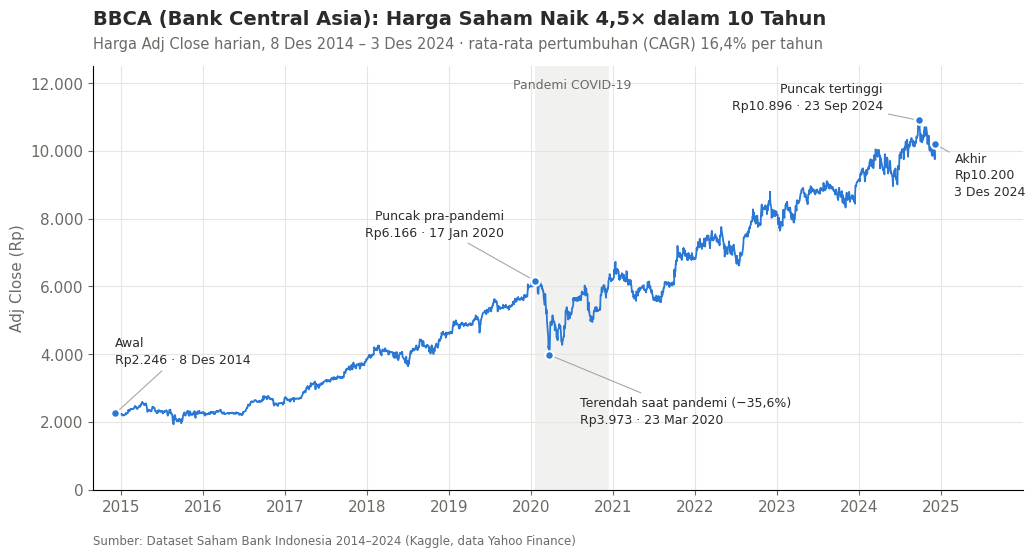

In [4]:
fig, ax = plt.subplots(figsize=(12, 5.5))

# pita periode pandemi: puncak pra-pandemi -> pulih
ax.axvspan(b_pra_tgl, b_pulih_tgl, color=B_PITA, alpha=0.13, lw=0, zorder=0)
ax.text(b_pra_tgl + (b_pulih_tgl - b_pra_tgl) / 2, 0.97, 'Pandemi COVID-19',
        transform=ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=9, color=B_TINTA_2)

ax.plot(b_harga.index, b_harga, color=WARNA[b_ticker], lw=1.3, zorder=2)

b_turun = (b_dasar / b_pra_harga - 1) * 100
b_anotasi = [
    # (tanggal, harga, teks, offset (pt), ha, va)
    (b_awal_tgl, b_awal, f'Awal\n{b_rp(b_awal)} · {b_tgl(b_awal_tgl)}', (0, 34), 'left', 'bottom'),
    (b_pra_tgl, b_pra_harga, f'Puncak pra-pandemi\n{b_rp(b_pra_harga)} · {b_tgl(b_pra_tgl)}',
     (-22, 30), 'right', 'bottom'),
    (b_dasar_tgl, b_dasar, f'Terendah saat pandemi ({b_angka(b_turun)}%)\n{b_rp(b_dasar)} · {b_tgl(b_dasar_tgl)}',
     (22, -30), 'left', 'top'),
    (b_puncak_tgl, b_puncak, f'Puncak tertinggi\n{b_rp(b_puncak)} · {b_tgl(b_puncak_tgl)}',
     (-26, 6), 'right', 'bottom'),
    (b_akhir_tgl, b_akhir, f'Akhir\n{b_rp(b_akhir)}\n{b_tgl(b_akhir_tgl)}', (14, -6), 'left', 'top'),
]
for tgl, nilai, teks, offset, ha, va in b_anotasi:
    ax.scatter(tgl, nilai, s=38, color=WARNA[b_ticker], edgecolor='white', linewidth=1.5, zorder=4)
    ax.annotate(teks, xy=(tgl, nilai), xytext=offset, textcoords='offset points',
                ha=ha, va=va, fontsize=9, color=B_TINTA, linespacing=1.35,
                arrowprops=dict(arrowstyle='-', color='#a8a7a1', lw=0.8, shrinkA=2, shrinkB=4))

b_judul(ax, f'{b_ticker} ({NAMA_BANK[b_ticker]}): Harga Saham Naik {b_angka(b_kali)}× dalam 10 Tahun',
        f'Harga Adj Close harian, {b_tgl(b_awal_tgl)} – {b_tgl(b_akhir_tgl)} · '
        f'rata-rata pertumbuhan (CAGR) {b_angka(b_cagr * 100)}% per tahun')
ax.set_ylabel('Adj Close (Rp)', color=B_TINTA_2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax.set_ylim(0, 12500)
ax.set_xlim(pd.Timestamp('2014-09-01'), pd.Timestamp('2025-12-31'))
format_tanggal(ax)
ax.tick_params(colors=B_TINTA_2)
b_sumber(ax)

simpan_fig(fig, '01_line_bbca')
plt.show()

**Insight:** Harga BBCA naik dari Rp2.246 (8 Des 2014) menjadi Rp10.200 (3 Des 2024), yaitu 4,5× atau rata-rata 16,4% per tahun, dengan arah naik yang konsisten hampir sepanjang periode. Koreksi terbesar terjadi saat pandemi COVID-19: harga turun 35,6% dari Rp6.166 (17 Jan 2020) ke Rp3.973 (23 Mar 2020), lalu kembali melewati level pra-pandemi pada 14 Des 2020, sekitar 9 bulan (266 hari) setelah titik terendah. Puncak tertinggi Rp10.896 dicapai pada 23 Sep 2024, dan di akhir data harga berada 6,4% di bawah puncak tersebut.

## Area Plot

Area plot dipakai untuk menekankan **volume perdagangan** (jumlah lembar saham yang ditransaksikan). Volume harian keempat bank dijumlahkan per bulan lalu ditumpuk (*stacked area*), sehingga tinggi total area menunjukkan volume gabungan keempat bank dan tebal tiap lapisan menunjukkan kontribusi masing-masing bank.

Bulan yang datanya tidak penuh dibuang supaya total bulanan sebanding: Desember 2014 (data mulai 8 Des) dan Desember 2024 (hanya sampai 3 Des). Periode yang dipakai: Januari 2015 – November 2024 (119 bulan). Satuan volume adalah miliar lembar (volume Yahoo Finance sudah disesuaikan dengan stock split).

In [5]:
b_vol_bulan = (vol_wide.resample('ME').sum() / 1e9).loc['2015-01':'2024-11']
b_total_bulan = b_vol_bulan.sum(axis=1)

b_vol_tahun = b_vol_bulan.groupby(b_vol_bulan.index.year).sum()
b_vol_tahun['Total'] = b_vol_tahun.sum(axis=1)
b_porsi = b_vol_bulan.sum() / b_vol_bulan.sum().sum() * 100

print(f'Rata-rata volume gabungan : {b_total_bulan.mean():.2f} miliar lembar/bulan')
b_bbri_teratas = (b_vol_bulan.idxmax(axis=1) == 'BBRI').sum()
print(f'Bulan tertinggi           : {b_bln(b_total_bulan.idxmax())} ({b_total_bulan.max():.2f} miliar lembar, '
      f'{b_total_bulan.max() / b_total_bulan.mean():.1f}x rata-rata)')
print('Porsi volume tiap bank (%):', b_porsi.round(1).to_dict())
print(f'BBRI volume terbesar di   : {b_bbri_teratas} dari {len(b_vol_bulan)} bulan')
print('\nVolume per tahun (miliar lembar; 2024 = Jan-Nov):')
b_vol_tahun.round(1)

Rata-rata volume gabungan : 7.97 miliar lembar/bulan
Bulan tertinggi           : Jun 2020 (16.81 miliar lembar, 2.1x rata-rata)
Porsi volume tiap bank (%): {'BBCA': 21.1, 'BBRI': 39.6, 'BMRI': 24.2, 'BBNI': 15.1}
BBRI volume terbesar di   : 115 dari 119 bulan

Volume per tahun (miliar lembar; 2024 = Jan-Nov):


Ticker,BBCA,BBRI,BMRI,BBNI,Total
Date,,,,,
2015,17.5,38.5,23.2,14.1,93.2
2016,23.1,33.7,22.8,13.5,93.0
2017,20.1,25.4,17.9,10.1,73.6
2018,18.5,32.1,17.9,10.6,79.1
2019,15.7,28.2,21.3,10.4,75.5
2020,25.6,53.1,30.7,27.2,136.6
2021,20.2,40.3,22.5,15.4,98.4
2022,23.4,40.8,28.6,16.1,108.9
2023,18.2,31.0,21.3,13.6,84.1


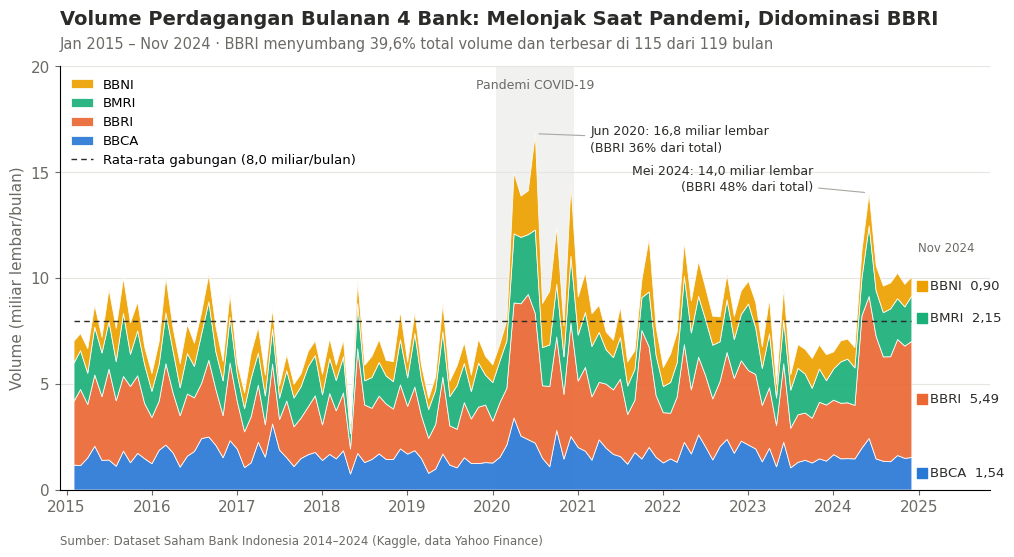

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.axvspan(b_pra_tgl, b_pulih_tgl, color=B_PITA, alpha=0.13, lw=0, zorder=0)
ax.text(b_pra_tgl + (b_pulih_tgl - b_pra_tgl) / 2, 0.97, 'Pandemi COVID-19',
        transform=ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=9, color=B_TINTA_2)

# urutan tumpukan bawah -> atas mengikuti TICKERS; garis putih tipis = jeda antar lapisan
ax.stackplot(b_vol_bulan.index, [b_vol_bulan[t] for t in TICKERS],
             colors=[WARNA[t] for t in TICKERS], labels=TICKERS,
             edgecolor='white', linewidth=0.6, alpha=0.92, zorder=2)

# label langsung di ujung kanan, di tengah tiap lapisan bulan terakhir
b_x_akhir = b_vol_bulan.index[-1]
b_atas = b_vol_bulan.iloc[-1].cumsum()
b_tengah = (b_atas - b_vol_bulan.iloc[-1] / 2).tolist()
for i in range(1, len(b_tengah)):           # jaga jarak minimal antar label
    b_tengah[i] = max(b_tengah[i], b_tengah[i - 1] + 1.3)
for t, y in zip(TICKERS, b_tengah):
    ax.scatter(b_x_akhir + pd.Timedelta(days=45), y, marker='s', s=42, color=WARNA[t], zorder=3)
    ax.text(b_x_akhir + pd.Timedelta(days=80), y,
            f'{t}  {b_angka(b_vol_bulan[t].iloc[-1], 2)}', va='center', fontsize=9.5, color=B_TINTA)
ax.text(b_x_akhir + pd.Timedelta(days=30), b_tengah[-1] + 1.5, b_bln(b_x_akhir),
        fontsize=8.5, color=B_TINTA_2, va='bottom')

# anotasi dua puncak volume gabungan
b_puncak_vol = [
    (b_total_bulan.idxmax(), (40, -4), 'left'),
    (b_total_bulan.loc['2021':].idxmax(), (-40, 10), 'right'),
]
for tgl, offset, ha in b_puncak_vol:
    total = b_total_bulan[tgl]
    porsi_bbri = b_vol_bulan.loc[tgl, 'BBRI'] / total * 100
    ax.annotate(f'{b_bln(tgl)}: {b_angka(total)} miliar lembar\n(BBRI {b_angka(porsi_bbri, 0)}% dari total)',
                xy=(tgl, total), xytext=offset, textcoords='offset points', ha=ha, va='center',
                fontsize=9, color=B_TINTA, linespacing=1.35,
                arrowprops=dict(arrowstyle='-', color='#a8a7a1', lw=0.8, shrinkA=2, shrinkB=3))

# garis rata-rata hanya sepanjang data, supaya tidak memotong label di kanan
ax.plot([b_vol_bulan.index[0], b_x_akhir], [b_total_bulan.mean()] * 2, color=B_TINTA,
        lw=1.0, ls=(0, (4, 3)), zorder=3,
        label=f'Rata-rata gabungan ({b_angka(b_total_bulan.mean())} miliar/bulan)')

b_judul(ax, 'Volume Perdagangan Bulanan 4 Bank: Melonjak Saat Pandemi, Didominasi BBRI',
        'Jan 2015 – Nov 2024 · '
        f'BBRI menyumbang {b_angka(b_porsi["BBRI"])}% total volume dan terbesar di '
        f'{b_bbri_teratas} dari {len(b_vol_bulan)} bulan')
ax.set_ylabel('Volume (miliar lembar/bulan)', color=B_TINTA_2)
ax.set_ylim(0, 20)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.set_xlim(b_vol_bulan.index[0] - pd.Timedelta(days=60), pd.Timestamp('2025-10-31'))
ax.grid(axis='x', visible=False)
format_tanggal(ax)
ax.tick_params(colors=B_TINTA_2)

# legend: lapisan urut sesuai tumpukan visual (atas -> bawah), lalu garis rata-rata
h, l = ax.get_legend_handles_labels()
ax.legend(h[:4][::-1] + h[4:], l[:4][::-1] + l[4:], loc='upper left', ncol=1, fontsize=9.5,
          handlelength=1.6, labelspacing=0.45, bbox_to_anchor=(0, 1.0))
b_sumber(ax)

simpan_fig(fig, '02_area_volume')
plt.show()

**Insight:** Volume gabungan keempat bank rata-rata 8,0 miliar lembar per bulan, dan BBRI menjadi penyumbang terbesar (39,6% dari total volume, terbesar di 115 dari 119 bulan). Lonjakan paling tajam terjadi saat pandemi: total volume 2020 mencapai 136,6 miliar lembar (naik 80,9% dari 2019) dengan puncak 16,8 miliar lembar pada Juni 2020 (2,1× rata-rata), dan volume BBNI pada 2020 naik 2,6× dibanding 2019. Lonjakan kedua pada Mei 2024 (14,0 miliar lembar) polanya berbeda karena hampir separuhnya (48%) berasal dari BBRI, sejalan dengan porsi BBRI sepanjang Jan–Nov 2024 yang naik menjadi 49,6%.